# Machine Learning No Supervisado — Parte 2: Reducción de dimensionalidad (PCA y SVD)

**Autor:** Harold Steven Rueda Lara · Universidad de Cundinamarca, Extensión Facatativá

**Objetivo.** Implementar el Análisis de Componentes Principales (PCA) y la Descomposición en Valores Singulares (SVD) con Scikit-learn y NumPy, interpretar la varianza explicada y las cargas de los componentes, demostrar la relación matemática entre PCA y SVD, y evaluar si trabajar en un espacio reducido afecta al clustering.

**Datos.** *Wine*: 178 vinos descritos por 13 variables químicas, de tres cultivares. Viene incluido en `sklearn.datasets`.

In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Liberation Serif', 'Times New Roman', 'DejaVu Serif'],
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 110,
})
os.makedirs('figuras', exist_ok=True)
os.makedirs('resultados', exist_ok=True)

SEED = 42          # semilla para que los resultados sean reproducibles
metricas = {}      # aquí se guardan las métricas que luego se usan en el informe
MARCADORES = ['o', 's', '^', 'D', 'v']

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

## 1. Datos y preparación
PCA busca las direcciones de máxima varianza; si una variable tiene una escala mucho mayor, dominaría los primeros componentes. Por eso se estandariza antes de aplicarlo.

In [2]:
wine = load_wine(as_frame=True)
X, y = wine.data, wine.target
cultivares = ['Cultivar 1', 'Cultivar 2', 'Cultivar 3']   # clases 0, 1 y 2 del dataset
variables = list(X.columns)
print('Dimensiones:', X.shape, '| variables:', len(variables))

Xs = StandardScaler().fit_transform(X)

Dimensiones: (178, 13) | variables: 13


## 2. PCA: varianza explicada

Componente  Varianza explicada (%)  Acumulada (%)
       PC1                   36.20          36.20
       PC2                   19.21          55.41
       PC3                   11.12          66.53
       PC4                    7.07          73.60
       PC5                    6.56          80.16
       PC6                    4.94          85.10
       PC7                    4.24          89.34
       PC8                    2.68          92.02
       PC9                    2.22          94.24
      PC10                    1.93          96.17
      PC11                    1.74          97.91
      PC12                    1.30          99.20
      PC13                    0.80         100.00

Componentes necesarios para >= 90% de la varianza: 8
Componentes necesarios para >= 95% de la varianza: 10


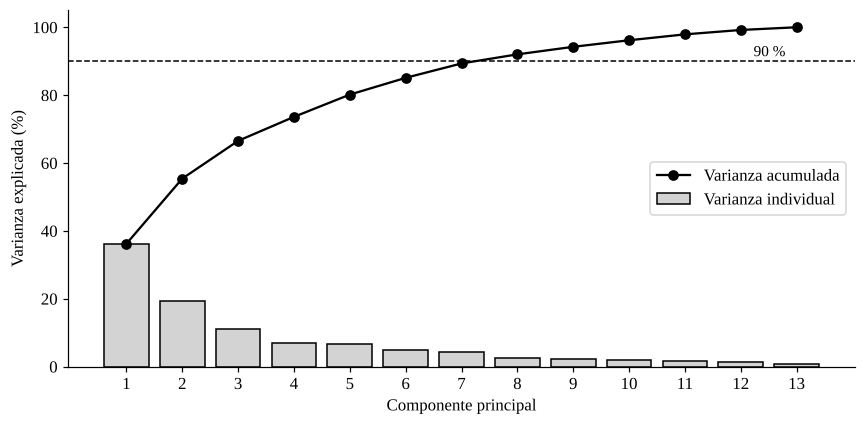

In [3]:
pca = PCA(random_state=SEED).fit(Xs)
var = pca.explained_variance_ratio_
acum = np.cumsum(var)
n90 = int(np.argmax(acum >= 0.90)) + 1
n95 = int(np.argmax(acum >= 0.95)) + 1

tabla_var = pd.DataFrame({'Componente': [f'PC{i+1}' for i in range(len(var))],
                          'Varianza explicada (%)': (var * 100).round(2),
                          'Acumulada (%)': (acum * 100).round(2)})
print(tabla_var.to_string(index=False))
print(f'\nComponentes necesarios para >= 90% de la varianza: {n90}')
print(f'Componentes necesarios para >= 95% de la varianza: {n95}')
metricas['pca_varianza'] = {'por_componente': var.tolist(), 'acumulada': acum.tolist(), 'n90': n90, 'n95': n95}

fig, ax = plt.subplots(figsize=(8, 4))
idx = np.arange(1, len(var) + 1)
ax.bar(idx, var * 100, color='lightgray', edgecolor='black', label='Varianza individual')
ax.plot(idx, acum * 100, marker='o', color='black', label='Varianza acumulada')
ax.axhline(90, color='black', linestyle='--', linewidth=1)
ax.text(len(var) - 0.2, 91.5, '90 %', ha='right', fontsize=10)
ax.set_xticks(idx); ax.set_xlabel('Componente principal'); ax.set_ylabel('Varianza explicada (%)')
ax.legend(loc='center right')
plt.tight_layout()
plt.savefig('figuras/fig5_varianza_pca.png', dpi=200, bbox_inches='tight')
plt.show()

## 3. PCA: proyección en 2D e interpretación de las cargas
Las **cargas** (*loadings*) indican cuánto aporta cada variable original a cada componente. Las flechas del gráfico (b) apuntan hacia donde crece cada variable en el plano de los dos primeros componentes.

Variables con mayor carga absoluta en PC1:
                                PC1    PC2
flavanoids                    0.423 -0.003
total_phenols                 0.395  0.065
od280/od315_of_diluted_wines  0.376 -0.164
proanthocyanins               0.313  0.039
nonflavanoid_phenols         -0.299  0.029

Variables con mayor carga absoluta en PC2:
                   PC1    PC2
color_intensity -0.089  0.530
alcohol          0.144  0.484
proline          0.287  0.365
ash             -0.002  0.316
magnesium        0.142  0.300


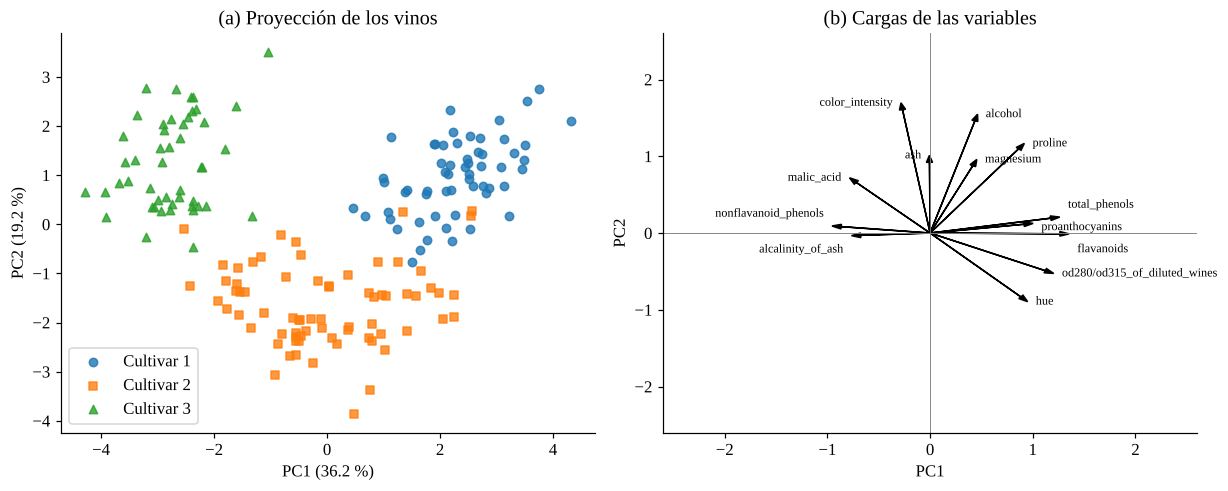

In [4]:
pca2 = PCA(n_components=2, random_state=SEED)
Z_pca = pca2.fit_transform(Xs)

cargas = pd.DataFrame(pca2.components_.T, index=variables, columns=['PC1', 'PC2'])
print('Variables con mayor carga absoluta en PC1:')
print(cargas.reindex(cargas['PC1'].abs().sort_values(ascending=False).index).head(5).round(3))
print('\nVariables con mayor carga absoluta en PC2:')
print(cargas.reindex(cargas['PC2'].abs().sort_values(ascending=False).index).head(5).round(3))
metricas['pca_cargas'] = {
    'PC1_top': cargas['PC1'].abs().sort_values(ascending=False).head(5).index.tolist(),
    'PC2_top': cargas['PC2'].abs().sort_values(ascending=False).head(5).index.tolist(),
    'cargas': cargas.round(4).to_dict(),
    'var_pc1': float(pca2.explained_variance_ratio_[0]), 'var_pc2': float(pca2.explained_variance_ratio_[1]),
}

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.6))
for c in range(3):
    ax[0].scatter(Z_pca[y == c, 0], Z_pca[y == c, 1], marker=MARCADORES[c], s=30, alpha=0.8, label=cultivares[c])
ax[0].set_xlabel(f'PC1 ({pca2.explained_variance_ratio_[0]*100:.1f} %)')
ax[0].set_ylabel(f'PC2 ({pca2.explained_variance_ratio_[1]*100:.1f} %)')
ax[0].set_title('(a) Proyección de los vinos'); ax[0].legend()

esc = 3.2
# desplazamientos manuales de las etiquetas que se solapan
ajuste = {'total_phenols': (0.0, 0.16), 'proanthocyanins': (0.0, -0.05), 'flavanoids': (0.0, -0.20),
          'nonflavanoid_phenols': (0.0, 0.16), 'alcalinity_of_ash': (0.0, -0.18)}
for i, v in enumerate(variables):
    px, py = cargas.iloc[i, 0] * esc, cargas.iloc[i, 1] * esc
    ax[1].arrow(0, 0, px, py, color='black', head_width=0.06, length_includes_head=True)
    dx, dy = ajuste.get(v, (0.0, 0.0))
    ax[1].text(px + (0.08 if px >= 0 else -0.08) + dx, py + dy, v, fontsize=8,
               ha='left' if px >= 0 else 'right', va='center')
ax[1].axhline(0, color='gray', linewidth=0.6); ax[1].axvline(0, color='gray', linewidth=0.6)
ax[1].set_xlim(-2.6, 2.6); ax[1].set_ylim(-2.6, 2.6)
ax[1].set_xlabel('PC1'); ax[1].set_ylabel('PC2'); ax[1].set_title('(b) Cargas de las variables')
plt.tight_layout()
plt.savefig('figuras/fig6_pca_proyeccion_cargas.png', dpi=200, bbox_inches='tight')
plt.show()

## 4. SVD y su relación con PCA

La SVD factoriza una matriz de datos centrada como **X = U Σ Vᵀ**. Las columnas de **V** son las direcciones principales (los componentes de PCA) y la varianza explicada por cada una es **σᵢ² / (n − 1)**. Se verifica numéricamente con NumPy.

In [5]:
Xc = Xs - Xs.mean(axis=0)
U, S, Vt = np.linalg.svd(Xc, full_matrices=False)

var_svd = S**2 / (Xc.shape[0] - 1)
print('Varianza por SVD  == varianza por PCA:', np.allclose(var_svd, pca.explained_variance_))
print('Direcciones (Vt)  == componentes PCA (salvo el signo):', np.allclose(np.abs(Vt), np.abs(pca.components_)))

Z_svd = U[:, :2] * S[:2]
print('Proyección U·Σ    == proyección PCA (salvo el signo):', np.allclose(np.abs(Z_svd), np.abs(Z_pca)))
print('\nPrimeros 5 valores singulares:', S[:5].round(3))
metricas['svd_equivalencia'] = {
    'varianza': bool(np.allclose(var_svd, pca.explained_variance_)),
    'direcciones': bool(np.allclose(np.abs(Vt), np.abs(pca.components_))),
    'proyeccion': bool(np.allclose(np.abs(Z_svd), np.abs(Z_pca))),
    'valores_singulares_5': S[:5].tolist(),
}

Varianza por SVD  == varianza por PCA: True
Direcciones (Vt)  == componentes PCA (salvo el signo): True
Proyección U·Σ    == proyección PCA (salvo el signo): True

Primeros 5 valores singulares: [28.942 21.082 16.044 12.79  12.324]


### 4.1 SVD truncado sin centrar
`TruncatedSVD` de Scikit-learn **no centra** los datos (por eso funciona con matrices dispersas). Si los datos no tienen media cero, el primer componente captura sobre todo la media y el resultado deja de coincidir con PCA. Se ilustra con los datos escalados al rango [0, 1], que no están centrados.

                          Método  Varianza explicada, 2 comp. (%)
             PCA (estandarizado)                            55.41
       SVD sobre datos centrados                            55.41
TruncatedSVD sin centrar ([0,1])                            51.07
                     PCA ([0,1])                            59.72

Ratio explicado por cada componente del TruncatedSVD sin centrar: [0.158 0.352]


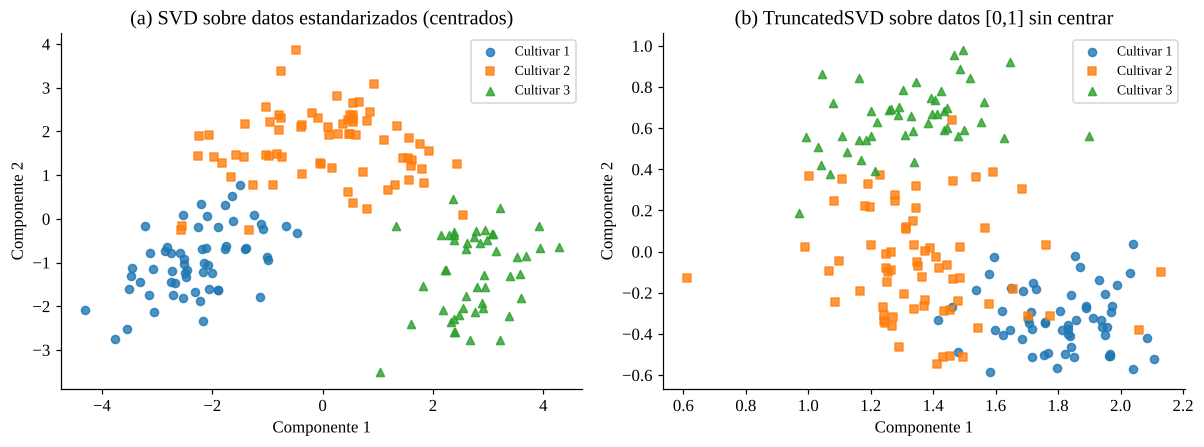

In [6]:
X01 = MinMaxScaler().fit_transform(X)

svd_sin_centrar = TruncatedSVD(n_components=2, random_state=SEED)
Z_t = svd_sin_centrar.fit_transform(X01)
pca_01 = PCA(n_components=2, random_state=SEED).fit(X01)

comp = pd.DataFrame({
    'Método': ['PCA (estandarizado)', 'SVD sobre datos centrados', 'TruncatedSVD sin centrar ([0,1])', 'PCA ([0,1])'],
    'Varianza explicada, 2 comp. (%)': [
        round(pca.explained_variance_ratio_[:2].sum() * 100, 2),
        round(var_svd[:2].sum() / var_svd.sum() * 100, 2),
        round(svd_sin_centrar.explained_variance_ratio_.sum() * 100, 2),
        round(pca_01.explained_variance_ratio_.sum() * 100, 2)],
})
print(comp.to_string(index=False))
print('\nRatio explicado por cada componente del TruncatedSVD sin centrar:', svd_sin_centrar.explained_variance_ratio_.round(3))
metricas['svd_comparacion'] = comp.to_dict(orient='records')

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for c in range(3):
    ax[0].scatter(Z_svd[y == c, 0], Z_svd[y == c, 1], marker=MARCADORES[c], s=28, alpha=0.8, label=cultivares[c])
    ax[1].scatter(Z_t[y == c, 0], Z_t[y == c, 1], marker=MARCADORES[c], s=28, alpha=0.8, label=cultivares[c])
ax[0].set_title('(a) SVD sobre datos estandarizados (centrados)')
ax[1].set_title('(b) TruncatedSVD sobre datos [0,1] sin centrar')
for a in ax:
    a.set_xlabel('Componente 1'); a.set_ylabel('Componente 2'); a.legend(fontsize=9)
plt.tight_layout()
plt.savefig('figuras/fig7_svd_proyecciones.png', dpi=200, bbox_inches='tight')
plt.show()

### 4.2 Aproximación de bajo rango y error de reconstrucción
Conservar solo los *r* mayores valores singulares da la mejor aproximación de rango *r* de la matriz (teorema de Eckart–Young). El error relativo de reconstrucción en norma de Frobenius es el complemento de la "energía" retenida.

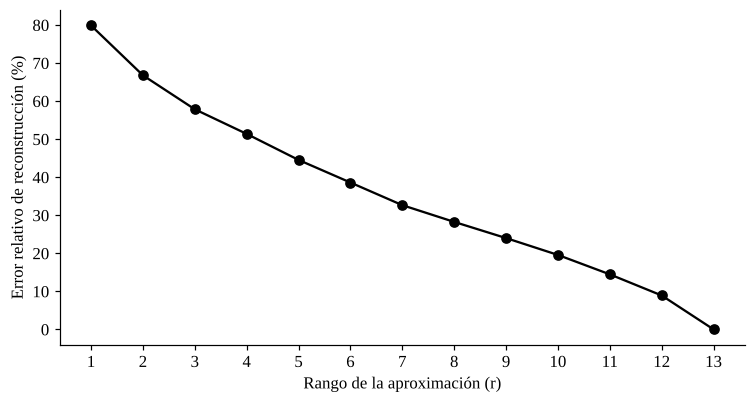

r =  2 -> error relativo = 66.8 %
r =  5 -> error relativo = 44.5 %
r =  8 -> error relativo = 28.3 %


In [7]:
errores = []
for r in range(1, len(S) + 1):
    Xr = (U[:, :r] * S[:r]) @ Vt[:r, :]
    errores.append(np.linalg.norm(Xc - Xr) / np.linalg.norm(Xc))

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(range(1, len(S) + 1), np.array(errores) * 100, marker='o', color='black')
ax.set_xticks(range(1, len(S) + 1))
ax.set_xlabel('Rango de la aproximación (r)'); ax.set_ylabel('Error relativo de reconstrucción (%)')
plt.tight_layout()
plt.savefig('figuras/fig8_error_reconstruccion.png', dpi=200, bbox_inches='tight')
plt.show()

for r in (2, 5, n90):
    print(f'r = {r:2d} -> error relativo = {errores[r-1]*100:.1f} %')
metricas['svd_error'] = {str(r): errores[r-1] for r in range(1, len(S) + 1)}

## 5. Aplicación: ¿el clustering funciona igual en el espacio reducido?
Se aplica K-means (*k* = 3) a los datos originales estandarizados (13 dimensiones) y a su versión reducida con PCA. La silueta de cada fila se calcula en su propio espacio, así que **no es estrictamente comparable entre filas**; el ARI sí lo es, porque compara con los cultivares reales.

In [8]:
configs = [('Original (13 dimensiones)', Xs),
           ('PCA 2 componentes', PCA(n_components=2, random_state=SEED).fit_transform(Xs)),
           (f'PCA {n90} componentes (90 % varianza)', PCA(n_components=n90, random_state=SEED).fit_transform(Xs))]
filas = []
for nombre, datos in configs:
    km = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(datos)
    filas.append({'Datos': nombre, 'Dimensiones': datos.shape[1],
                  'ARI': round(adjusted_rand_score(y, km.labels_), 3),
                  'Silueta': round(silhouette_score(datos, km.labels_), 3)})
tabla_app = pd.DataFrame(filas)
print(tabla_app.to_string(index=False))
metricas['kmeans_en_espacio_reducido'] = tabla_app.to_dict(orient='records')

                            Datos  Dimensiones   ARI  Silueta
        Original (13 dimensiones)           13 0.897    0.285
                PCA 2 componentes            2 0.895    0.561
PCA 8 componentes (90 % varianza)            8 0.897    0.315


## 6. Análisis de resultados

**Varianza explicada.** Los dos primeros componentes retienen el 55,4 % de la varianza (PC1 = 36,2 %; PC2 = 19,2 %). Se necesitan 8 componentes para llegar al 90 % y 10 para el 95 %. Las 13 variables tienen redundancia moderada, pero no extrema: la compresión útil es de 13 a 8 dimensiones, no a 2 o 3.

**Interpretación de los componentes.** PC1 está dominado por flavonoides, fenoles totales, OD280/OD315 y proantocianinas (con signo positivo) y por los fenoles no flavonoides (con signo negativo): se asocia con el contenido fenólico del vino. PC2 recoge sobre todo la intensidad del color, el alcohol y la prolina. En el plano de los dos componentes, los tres cultivares se distinguen con claridad, con un leve solapamiento entre los cultivares 1 y 2.

**PCA y SVD son la misma operación.** Con los datos centrados, los valores singulares cumplen σᵢ²/(n − 1) = varianza de cada componente, y las direcciones de **V** y la proyección **U·Σ** coinciden con las de PCA, salvo el signo (que es arbitrario). Las tres comprobaciones numéricas dieron `True`.

**Importancia de centrar.** `TruncatedSVD` no centra los datos. Sobre los datos en [0, 1] retiene el 51,1 % de la varianza con 2 componentes, frente al 59,7 % de PCA sobre los mismos datos, porque su primer componente absorbe la media. Para obtener PCA con SVD hay que centrar primero.

**Reconstrucción.** El error relativo de la aproximación de rango *r* es igual a √(1 − varianza acumulada): 66,8 % con *r* = 2, 44,5 % con *r* = 5 y 28,3 % con *r* = 8. Reducir mucho las dimensiones tiene un costo en información, que debe decidirse según el objetivo.

**Efecto en el clustering.** K-means obtiene prácticamente el mismo ARI con 13 dimensiones (0,897), con 8 componentes (0,897) y con solo 2 componentes (0,895). Es decir, aunque 2 componentes retienen solo el 55 % de la varianza, la información que separa los cultivares queda casi intacta, y se gana visualización y menor costo de cálculo. Las siluetas (0,285; 0,315 y 0,561) no son comparables entre sí porque se miden en espacios distintos.

**Limitaciones.** PCA es lineal: no captura estructuras curvas. Sus componentes son combinaciones de variables y pueden ser difíciles de interpretar, y depende de la escala (por eso se estandarizó). Los resultados corresponden a un solo conjunto de datos pequeño.

In [9]:
with open('resultados/metricas_reduccion_dimensionalidad.json', 'w', encoding='utf-8') as f:
    json.dump(metricas, f, ensure_ascii=False, indent=2, default=float)
print('Métricas guardadas en resultados/metricas_reduccion_dimensionalidad.json')

Métricas guardadas en resultados/metricas_reduccion_dimensionalidad.json
